In [2]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

print("Available GPUs:", gpus)

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

TensorFlow Version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import random
import os
import time

from collections import Counter

from datasets import load_dataset

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models, regularizers

from tensorflow.keras.applications import EfficientNetB0

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger
)

sns.set_style("whitegrid")

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)


In [4]:
ds = load_dataset("TrashBusters/combined")


README.md:   0%|          | 0.00/12.1k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  506MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  445MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  501MB            

... (4 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/20894 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4477 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4478 [00:00<?, ? examples/s]

In [5]:
IMG_SIZE = 224
BATCH_SIZE = 32


In [6]:
def preprocess_image(image):

    image = np.array(image)

    # Handle grayscale images
    if image.ndim == 2:

        image = cv2.cvtColor(
            image,
            cv2.COLOR_GRAY2RGB
        )

    # Handle RGBA images
    elif image.shape[-1] == 4:

        image = cv2.cvtColor(
            image,
            cv2.COLOR_RGBA2RGB
        )

    # Resize image
    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )

    return image.astype(np.uint8)


In [7]:
def create_tf_dataset(hf_dataset, training=False):

    def generator():

        for sample in hf_dataset:

            image = preprocess_image(
                sample["image"]
            )

            label = np.int32(
                sample["label"]
            )

            yield image, label

    dataset = tf.data.Dataset.from_generator(

        generator,

        output_signature=(

            tf.TensorSpec(
                shape=(IMG_SIZE, IMG_SIZE, 3),
                dtype=tf.uint8
            ),

            tf.TensorSpec(
                shape=(),
                dtype=tf.int32
            )
        )
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=3000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


In [8]:
train_data = create_tf_dataset(
    ds["train"],
    training=True
)

validation_data = create_tf_dataset(
    ds["validation"]
)

test_data = create_tf_dataset(
    ds["test"]
)


In [9]:
for images, labels in train_data.take(1):

    print("Image Shape:", images.shape)
    print("Label Shape:", labels.shape)
    print("Image Data Type:", images.dtype)
    print("Label Data Type:", labels.dtype)


Image Shape: (32, 224, 224, 3)
Label Shape: (32,)
Image Data Type: <dtype: 'uint8'>
Label Data Type: <dtype: 'int32'>


In [10]:
class_names = ds["train"].features["label"].names

NUM_CLASSES = len(class_names)


y_train = np.array(ds["train"]["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(
        np.unique(y_train),
        weights
    )
}

print("Class Weights:")

for i, name in enumerate(class_names):

    print(name, ":", class_weights[i])


Class Weights:
cardboard : 1.0260263209585543
glass : 0.9949523809523809
metal : 0.9949523809523809
paper : 0.9949523809523809
plastic : 0.9949523809523809
trash : 0.9949523809523809


In [11]:
data_augmentation = models.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.10),

    layers.RandomZoom(0.10),

    layers.RandomContrast(0.10)

])


In [12]:
base_model = EfficientNetB0(

    weights="imagenet",

    include_top=False,

    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [13]:
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = data_augmentation(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,416,297 (16.85 MB)

 Trainable params: 364,166 (1.39 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [14]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)


In [15]:
checkpoint_head = ModelCheckpoint(
    "/content/best_model_head.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

early_stop_head = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr_head = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6
)


In [16]:
IMG_SIZE = 224
BATCH_SIZE = 32

EPOCHS_HEAD = 15
EPOCHS_FINE = 15


In [ ]:
start_time = time.time()

history_head = model.fit(

    train_data,

    validation_data=validation_data,

    epochs=EPOCHS_HEAD,

    class_weight=class_weights,

    callbacks=[
        checkpoint_head,
        early_stop_head,
        reduce_lr_head
    ]
)

print(
    "Training Time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)


Epoch 1/15
    653/Unknown 170s 203ms/step - accuracy: 0.5641 - loss: 1.3153

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


653/653 ━━━━━━━━━━━━━━━━━━━━ 208s 261ms/step - accuracy: 0.6621 - loss: 1.0198 - val_accuracy: 0.8356 - val_loss: 0.5385 - learning_rate: 3.0000e-04
Epoch 2/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 187s 256ms/step - accuracy: 0.7639 - loss: 0.7250 - val_accuracy: 0.8555 - val_loss: 0.4863 - learning_rate: 3.0000e-04
Epoch 3/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 210s 293ms/step - accuracy: 0.7958 - loss: 0.6439 - val_accuracy: 0.8631 - val_loss: 0.4539 - learning_rate: 3.0000e-04
Epoch 4/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 243s 262ms/step - accuracy: 0.8125 - loss: 0.5904 - val_accuracy: 0.8707 - val_loss: 0.4336 - learning_rate: 3.0000e-04
Epoch 5/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 188s 257ms/step - accuracy: 0.8321 - loss: 0.5515 - val_accuracy: 0.8807 - val_loss: 0.4128 - learning_rate: 3.0000e-04
Epoch 6/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 190s 262ms/step - accuracy: 0.8397 - loss: 0.5211 - val_accuracy: 0.8839 - val_loss: 0.4074 - learning_rate: 3.0000e-04
Epoch 7/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 188s 256ms/

In [ ]:
#fine tuning

base_model.trainable = True

for layer in base_model.layers[:-40]:
    layer.trainable = False

for layer in base_model.layers:

    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False


In [ ]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)


In [ ]:
checkpoint_fine = ModelCheckpoint(
    "/content/best_model_finetuned.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

early_stop_fine = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr_fine = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7
)


In [ ]:
start_time = time.time()

history_fine = model.fit(

    train_data,

    validation_data=validation_data,

    epochs=EPOCHS_FINE,

    class_weight=class_weights,

    callbacks=[
        checkpoint_fine,
        early_stop_fine,
        reduce_lr_fine
    ]
)

print(
    "Fine-tuning Time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)


Epoch 1/15
    653/Unknown 172s 216ms/step - accuracy: 0.8912 - loss: 0.3808

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


653/653 ━━━━━━━━━━━━━━━━━━━━ 207s 269ms/step - accuracy: 0.8977 - loss: 0.3625 - val_accuracy: 0.9042 - val_loss: 0.3655 - learning_rate: 1.0000e-05
Epoch 2/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 186s 257ms/step - accuracy: 0.8995 - loss: 0.3492 - val_accuracy: 0.9060 - val_loss: 0.3635 - learning_rate: 1.0000e-05
Epoch 3/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 189s 260ms/step - accuracy: 0.9094 - loss: 0.3286 - val_accuracy: 0.9060 - val_loss: 0.3610 - learning_rate: 1.0000e-05
Epoch 4/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 189s 260ms/step - accuracy: 0.9126 - loss: 0.3239 - val_accuracy: 0.9075 - val_loss: 0.3559 - learning_rate: 1.0000e-05
Epoch 5/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 187s 257ms/step - accuracy: 0.9151 - loss: 0.3159 - val_accuracy: 0.9080 - val_loss: 0.3546 - learning_rate: 1.0000e-05
Epoch 6/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 190s 262ms/step - accuracy: 0.9135 - loss: 0.3092 - val_accuracy: 0.9098 - val_loss: 0.3526 - learning_rate: 1.0000e-05
Epoch 7/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 202s 281ms/

In [ ]:
model = tf.keras.models.load_model(
    "/content/best_model_head.keras"
)

base_model = model.get_layer("efficientnetb0")
base_model.trainable = True

for layer in base_model.layers[:-80]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.000005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


Trainable layers: 63


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.000005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [ ]:
checkpoint_80 = ModelCheckpoint(
    "/content/best_model_80layers.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

early_stop_80 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr_80 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7
)


In [ ]:
start_time = time.time()

history_80 = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    class_weight=class_weights,
    callbacks=[
        checkpoint_80,
        early_stop_80,
        reduce_lr_80
    ]
)

print(
    "Training Time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)


Epoch 1/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 209s 269ms/step - accuracy: 0.8974 - loss: 0.3643 - val_accuracy: 0.9046 - val_loss: 0.3653 - learning_rate: 5.0000e-06
Epoch 2/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 195s 268ms/step - accuracy: 0.9006 - loss: 0.3495 - val_accuracy: 0.9046 - val_loss: 0.3619 - learning_rate: 5.0000e-06
Epoch 3/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 191s 264ms/step - accuracy: 0.9049 - loss: 0.3401 - val_accuracy: 0.9069 - val_loss: 0.3588 - learning_rate: 5.0000e-06
Epoch 4/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 192s 266ms/step - accuracy: 0.9101 - loss: 0.3316 - val_accuracy: 0.9078 - val_loss: 0.3555 - learning_rate: 5.0000e-06
Epoch 5/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 194s 267ms/step - accuracy: 0.9136 - loss: 0.3191 - val_accuracy: 0.9091 - val_loss: 0.3510 - learning_rate: 5.0000e-06
Epoch 6/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 187s 258ms/step - accuracy: 0.9144 - loss: 0.3124 - val_accuracy: 0.9089 - val_loss: 0.3519 - learning_rate: 5.0000e-06
Epoch 7/15
653/653 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
results = {
    "Phase 1": {
        "accuracy": max(history_head.history["val_accuracy"]),
        "loss": min(history_head.history["val_loss"])
    },

    "40 Layers": {
        "accuracy": max(history_fine.history["val_accuracy"]),
        "loss": min(history_fine.history["val_loss"])
    },

    "80 Layers": {
        "accuracy": max(history_80.history["val_accuracy"]),
        "loss": min(history_80.history["val_loss"])
    }
}

for name, metrics in results.items():
    print(f"\n{name}")
    print("Best Validation Accuracy:", round(metrics["accuracy"] * 100, 2), "%")
    print("Best Validation Loss:", round(metrics["loss"], 4))



Phase 1
Best Validation Accuracy: 90.26 %
Best Validation Loss: 0.3726

40 Layers
Best Validation Accuracy: 91.65 %
Best Validation Loss: 0.3402

80 Layers
Best Validation Accuracy: 91.27 %
Best Validation Loss: 0.3382


In [ ]:
best_model = tf.keras.models.load_model(
    "/content/best_model_finetuned.keras"
)
test_loss, test_accuracy = best_model.evaluate(test_data)

print("Test Accuracy:", test_accuracy * 100)
print("Test Loss:", test_loss)


140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 217ms/step - accuracy: 0.9209 - loss: 0.3391
Test Accuracy: 92.09468364715576
Test Loss: 0.3390623927116394


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in test_data:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)


In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

   cardboard       0.92      0.96      0.94       728
       glass       0.96      0.95      0.95       750
       metal       0.92      0.95      0.93       750
       paper       0.91      0.87      0.89       750
     plastic       0.89      0.87      0.88       750
       trash       0.92      0.93      0.92       750

    accuracy                           0.92      4478
   macro avg       0.92      0.92      0.92      4478
weighted avg       0.92      0.92      0.92      4478



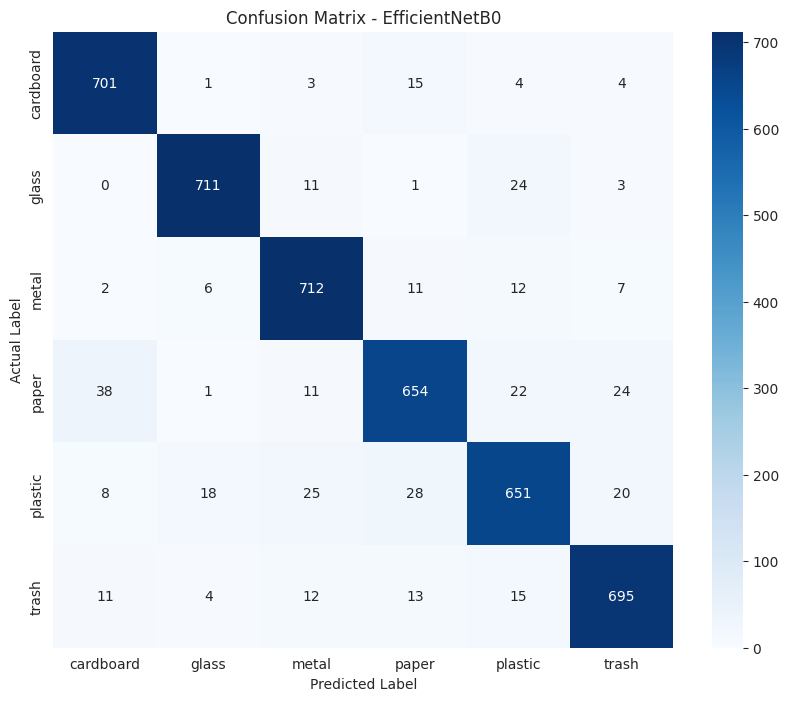

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - EfficientNetB0")
plt.show()


In [ ]:
best_model.save("/content/waste_classifier.keras")
from google.colab import files

files.download("/content/waste_classifier.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

files.download("/content/class_names.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>